# 02 Data Preparation, EDA and Popularity Baseline
Week 2 deliverables: cleaned data, sparsity analysis, most active users and popular items, and a popularity baseline with Top-N output.

**Pipeline:** raw transactions -> collapse same-day repeats -> sensitivity analysis -> leakage-safe filter/sample -> cleaned interactions -> time-based split -> interaction matrix -> popularity baseline.

Every filtering choice is controlled in `src/config.py` and justified from the tables below; change a value there and re-run.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config, data_audit as da, prepare as prep, evaluation as ev

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.IMAGES_DIR.mkdir(exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(config.IMAGES_DIR / name, dpi=150)
    plt.show()

## 1. Load and collapse same-day repeats

In [2]:
customers = da.load_customers()
articles = da.load_articles()
articles_by_id = articles.set_index("article_id")
raw = da.load_transactions(customer_ids=customers["customer_id"])
tx = prep.collapse_same_day(raw)
print(f"rows before: {len(raw):,} | interactions after collapsing same customer+article+day: {len(tx):,} "
      f"({1 - len(tx) / len(raw):.2%} of rows merged)")
display(tx["n_units"].value_counts().sort_index().head(8).rename("interactions").to_frame())
del raw

rows before: 31,788,324 | interactions after collapsing same customer+article+day: 28,575,395 (10.11% of rows merged)


,interactions
n_units,
1,25857551
2,2418787
3,205350
4,63677
5,10207
6,10013
7,1984
8,2429


**Why collapse.** Week 1 found 9.36% exact duplicate rows. Most are the same item bought several times on one day (typically different sizes, which the data does not record). That is one *preference* expressed several times, so it is treated as one interaction with `n_units` kept as an optional weight. Repeats on *different* days are kept, because they show real re-purchase behaviour.

## 2. Sensitivity analysis: how filters change the dataset
Each row is the dataset that would result from a time window, a minimum number of *distinct items per user* and a minimum number of *distinct buyers per item*, both measured on the **training period only** (the last validation and test days are excluded from the counts), with the same seeded user sample the final pipeline uses. `interactions` counts all periods of the surviving users and items.

In [3]:
windows = {"last 3 months": 91, "last 6 months": 182, "last 12 months": 365, "all history": None}
sens = prep.sensitivity_table(tx, windows, min_users=(1, 5, 10), min_items=(1, 20, 50),
                              sample_users=config.SAMPLE_USERS, seed=config.RANDOM_SEED)
display(sens)

,window,min_user,min_item,users_in_train,users_eligible,users,items,interactions,interactions_per_user,sparsity
0,last 3 months,1,1,432539,432539,50000,23658,357050,7.1410,0.9997
1,last 3 months,1,20,432539,432539,45648,4103,232910,5.1023,0.9988
2,last 3 months,1,50,432539,432539,37734,1336,130021,3.4457,0.9975
3,last 3 months,5,1,432539,191091,50000,27363,615560,12.3112,0.9996
4,last 3 months,5,20,432539,191091,39521,6051,423315,10.7111,0.9983
5,last 3 months,5,50,432539,191091,16444,1379,138613,8.4294,0.9942
6,last 3 months,10,1,432539,73135,50000,30640,974565,19.4913,0.9994
7,last 3 months,10,20,432539,73135,38044,7941,688560,18.0990,0.9978
8,last 3 months,10,50,432539,73135,0,0,0,NaN,NaN
9,last 6 months,1,1,690821,690821,50000,28676,504919,10.0984,0.9997


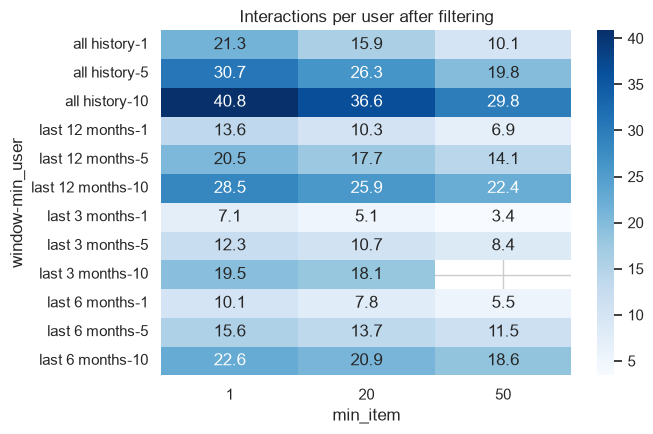

In [4]:
pivot = sens.pivot_table(index=["window", "min_user"], columns="min_item", values="interactions_per_user")
plt.figure(figsize=(7, 4.5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues")
plt.title("Interactions per user after filtering")
save_fig("sensitivity_interactions_per_user.png")

**How to choose.** A good working set (a) keeps enough history per user to learn from and still leave something to test on, (b) keeps items with enough evidence, (c) stays small enough to iterate quickly, and (d) does not distort popularity patterns by cutting too aggressively. Fashion is seasonal, so a window shorter than a year hides the seasonal cycle. Write your own justification in section 12 after reading this table.

## 3. Apply the chosen filters (leakage-safe)
Thresholds are measured on the training period only. Users and items that pass form a fixed *universe*; all their window interactions are kept, including validation and test ones. Validation/test purchases by universe users of items outside the universe (new or rarely bought items) are kept separately as `cold_items` for a dedicated cold-start analysis. Users with no training history are excluded from the main comparison and need a popularity fallback in a live system.

In [5]:
spec = prep.PrepSpec()   # values come from src/config.py
print(spec)
prepared = prep.prepare_working_set(tx, spec)
display(prepared.report)
prep.save_prepared(prepared)
cleaned, cold_items = prepared.cleaned, prepared.cold_items
print("Saved to", config.CLEANED_DIR, "| validation starts", prepared.meta["val_start"], "| test starts", prepared.meta["test_start"])

PrepSpec(window_days=365, min_user_interactions=5, min_item_interactions=20, sample_users=50000, seed=42, val_days=14, test_days=14)


,interactions,users,items
step,,,
collapsed input,"28,575,395.0000",1362281,"104,547.0000"
time window (365 days),"13,393,577.0000",993492,"70,840.0000"
training period of the window (before 2020-08-26),"12,446,931.0000",961411,"67,367.0000"
users with >= 5 distinct training items,NaN,592716,NaN
"universe: sample <= 50000 users, k-core (user>=5 items, item>=20 buyers)",NaN,45078,"11,916.0000"
"cleaned interactions (all periods, inside universe)","797,912.0000",45078,"11,916.0000"
"cold-item interactions (val/test, items outside universe)","32,690.0000",10537,"7,136.0000"


Saved to C:\Users\HP\Documents\DSA4060\Final project\DSA4060XA-Recommender-Project-1\data\cleaned | validation starts 2020-08-26 | test starts 2020-09-09


## 4. Sparsity of the cleaned interaction matrix

users 45,078 | items 11,916 | non-empty cells 762,426
sparsity 99.8581% | density 0.1419%


,per user,per item
count,"45,078.0000","11,916.0000"
mean,16.9135,63.9834
std,15.6074,64.3354
min,5.0000,20.0000
25%,7.0000,29.0000
50%,12.0000,44.0000
75%,20.0000,74.0000
max,294.0000,"1,542.0000"


Gini of item popularity: 0.404


,share of interactions
top 1%,0.0728
top 5%,0.2119
top 10%,0.3245
top 20%,0.4837


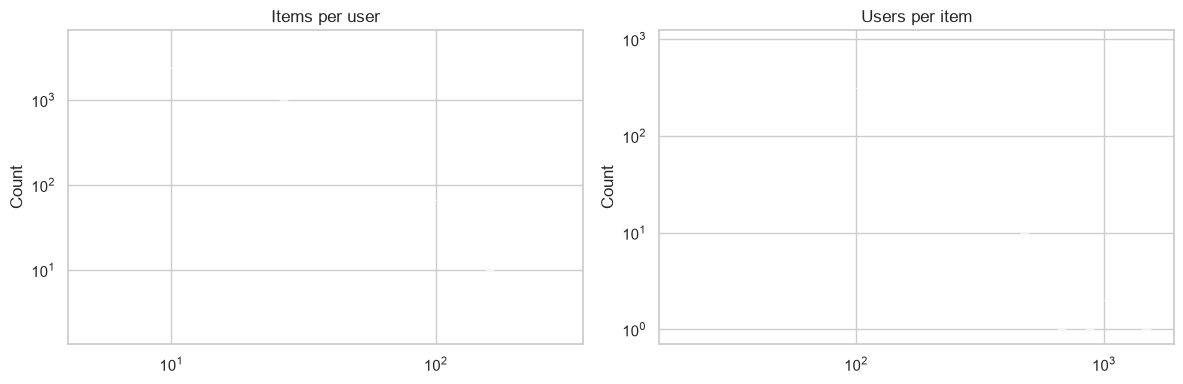

In [6]:
users, items = prep.make_index(cleaned)
matrix = prep.build_interaction_matrix(cleaned, users, items, weighting="binary")
n_u, n_i = matrix.shape
print(f"users {n_u:,} | items {n_i:,} | non-empty cells {matrix.nnz:,}")
print(f"sparsity {prep.matrix_sparsity(matrix):.4%} | density {matrix.nnz / (n_u * n_i):.4%}")
per_user, per_item = matrix.getnnz(axis=1), matrix.getnnz(axis=0)
display(pd.DataFrame({"per user": pd.Series(per_user).describe(), "per item": pd.Series(per_item).describe()}))
print("Gini of item popularity:", round(da.gini(pd.Series(per_item)), 4))
display(da.concentration_table(pd.Series(per_item)).rename("share of interactions").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, vals, title in zip(axes, [per_user, per_item], ["Items per user", "Users per item"]):
    sns.histplot(vals, bins=50, log_scale=(True, True), ax=ax); ax.set_title(title)
save_fig("cleaned_activity_distributions.png")

## 5. Most active users and most popular items

In [7]:
top_users = pd.Series(per_user, index=users).sort_values(ascending=False).head(10).rename("distinct items bought")
display(top_users.to_frame())

pop = pd.Series(per_item, index=items).sort_values(ascending=False).head(15).rename("buyers")
meta = articles_by_id.loc[pop.index, ["prod_name", "product_code", "product_type_name", "colour_group_name"]]
top_items = pop.to_frame().join(meta)
display(top_items)
print("Distinct product_code among the top 15 articles:", top_items["product_code"].nunique())

,distinct items bought
customer_id,
d80ed4ababfa96812e22b911629e6bcbf5093769051ea447e2b696ac98a3dae9,294
6cc121e5cc202d2bf344ffe795002bdbf87178054bcda2e57161f0ef810a4b55,290
8df45859ccd71ef1e48e2ee9d1c65d5728c31c46ae957d659fa4e5c3af6cc076,248
950159306933d969b06b43f21a92a29fd37ed81ed8786af2dee5f6a22f8b553c,237
7a859c4f0a3aeea904d8436153f3f6c4eebf2e99b485c6c6f89877d6797eec98,228
6881f635c5be0550646522a81a07d942ee71fcf603397d7908b76b1df2298745,221
29a5773da1accdbebeac55aa80da6863904668e8d009d5ee57dd92c53f43b7ea,216
788785852eddb5874f924603105f315d69571b3e5180f3a7ae6970b55b6d5dc9,211
26cc4ed150c2f7ed29e8aaff46b5f7d99a40640113c3c2b6572944c73d653745,206


,buyers,prod_name,product_code,product_type_name,colour_group_name
706016001,1542,Jade HW Skinny Denim TRS,706016,Trousers,Black
720125001,1069,SUPREME RW tights,720125,Leggings/Tights,Black
372860001,1029,7p Basic Shaftless,372860,Socks,Black
759871002,946,Tilda tank,759871,Vest top,Black
706016002,925,Jade HW Skinny Denim TRS,706016,Trousers,Light Blue
610776002,884,Tilly (1),610776,T-shirt,Black
372860002,814,7p Basic Shaftless,372860,Socks,White
464297007,792,Greta Thong Mynta Low 3p,464297,Underwear bottom,Black
751471001,775,Pluto RW slacks (1),751471,Trousers,Black
706016003,756,Jade HW Skinny Denim TRS,706016,Trousers,Dark Blue


Distinct product_code among the top 15 articles: 11


If several top articles share a `product_code`, they are colour variants of one design. A raw popularity list then repeats the same product, which hurts diversity. This is evidence for de-duplicating Top-N lists by product in later weeks.

## 6. Does popularity drift, and how fast does the catalogue turn over?

In [8]:
last_days = cleaned[cleaned["t_dat"] >= cleaned["t_dat"].max() - pd.Timedelta(days=13)]
top_recent = set(last_days["article_id"].value_counts().head(100).index)
top_overall = set(cleaned["article_id"].value_counts().head(100).index)
print("Overlap of top-100 items (last 14 days vs whole window):", len(top_recent & top_overall), "of 100")

# Catalogue turnover over ALL customers (before filtering): purchases of items not sold earlier in the window
val_start, test_start = pd.Timestamp(prepared.meta["val_start"]), pd.Timestamp(prepared.meta["test_start"])
window_tx = tx[tx["t_dat"] >= tx["t_dat"].max() - pd.Timedelta(days=(config.WINDOW_DAYS or 10**6) - 1)]
sold_before = set(window_tx.loc[window_tx["t_dat"] < val_start, "article_id"])
for name, part in (("validation", window_tx[(window_tx["t_dat"] >= val_start) & (window_tx["t_dat"] < test_start)]),
                   ("test", window_tx[window_tx["t_dat"] >= test_start])):
    print(f"{name}: {(~part['article_id'].isin(sold_before)).mean():.2%} of all purchases are of items not sold earlier in the window")

Overlap of top-100 items (last 14 days vs whole window): 36 of 100
validation: 6.49% of all purchases are of items not sold earlier in the window
test: 25.16% of all purchases are of items not sold earlier in the window


A low overlap means popularity changes quickly, which is the reason to compare recency-weighted popularity with plain popularity. The turnover figures show how much of the catalogue is new at evaluation time, which limits what any collaborative model can recommend and motivates content features for new items.

## 7. Time-based split

In [9]:
split = prep.time_split(cleaned, val_start, test_start)
print("validation starts", split.val_start.date(), "| test starts", split.test_start.date())
display(prep.split_report(split, cold_items))

validation starts 2020-08-26 | test starts 2020-09-09


,from,to,interactions,users,items,users also in train,interactions on items not in train,cold-item interactions excluded
part,,,,,,,,
train,2019-09-24,2020-08-25,769314,45078,11916,NaN,NaN,NaN
validation,2020-08-26,2020-09-08,16574,6698,4171,1.0000,0.0000,"15,749.0000"
test,2020-09-09,2020-09-22,12024,5385,3523,1.0000,0.0000,"16,941.0000"


A random split would leak the future into training, so the data is split by time: train, then validation, then test. Models are tuned on validation only; the test block is touched once, in Week 4. Because users and items were chosen from the training period, every evaluated user and item has training history by construction; the cold-item interactions that this excludes are counted in the last column so the limitation is visible.

## 8. Popularity baseline: global and recency-weighted

In [10]:
train_m = prep.build_interaction_matrix(split.train, users, items, "binary")
val_m = prep.build_interaction_matrix(split.val, users, items, "binary")
eval_users = np.flatnonzero(val_m.getnnz(axis=1) > 0)
item_share = train_m.getnnz(axis=0) / train_m.shape[0]
print(f"{len(eval_users):,} validation users with at least one purchase; "
      f"{(train_m.getnnz(axis=1)[eval_users] > 0).mean():.2%} have train history")

variants = {"global popularity": None, **{f"recency half-life {h}d": h for h in config.HALF_LIVES_DAYS}}
scores = {name: prep.popularity_scores(split.train, items, h) for name, h in variants.items()}
recs = {name: prep.recommend_popular(s, train_m, eval_users, config.TOP_K, exclude_seen=True)
        for name, s in scores.items()}
results = pd.DataFrame({name: ev.evaluate_topk(r, val_m, eval_users, item_share, len(items))
                        for name, r in recs.items()}).T
display(results)
best = results[f"NDCG@{config.TOP_K}"].idxmax()
print("Best baseline on validation (NDCG):", best)

6,698 validation users with at least one purchase; 100.00% have train history


,Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,users evaluated
global popularity,0.0045,0.0178,0.0111,0.0013,5.6903,0.0199,"6,698.0000"
recency half-life 1d,0.0076,0.0354,0.0196,0.0012,9.1761,0.0044,"6,698.0000"
recency half-life 3d,0.0076,0.0349,0.0197,0.0012,8.2033,0.0073,"6,698.0000"
recency half-life 5d,0.0074,0.0339,0.0193,0.0012,8.1849,0.0073,"6,698.0000"
recency half-life 7d,0.0072,0.0325,0.0187,0.0012,8.0651,0.0075,"6,698.0000"
recency half-life 14d,0.0063,0.0266,0.0162,0.0012,6.9115,0.0124,"6,698.0000"
recency half-life 28d,0.0049,0.0206,0.0126,0.0013,6.1427,0.0164,"6,698.0000"
recency half-life 56d,0.0041,0.0168,0.0111,0.0013,5.8777,0.0178,"6,698.0000"


Best baseline on validation (NDCG): recency half-life 3d


**Reading this table.** Popularity gives almost every user the same list (only items they already bought are removed), so coverage is tiny and novelty low. That is the expected weakness of the baseline, and the personalised models in Weeks 3 and 4 are judged against these numbers. Exclusion of already-bought items is a design choice: fashion has repeat purchases, so Week 4 should report results with and without it.

## 9. Example Top-N lists

In [11]:
rng = np.random.default_rng(config.RANDOM_SEED)
sample_users = rng.choice(eval_users, 5, replace=False)
sample_recs = prep.recommend_popular(scores[best], train_m, sample_users, config.TOP_K)
name_of = lambda idx: articles_by_id.loc[items[idx], "prod_name"].tolist()
rows = []
for u, r in zip(sample_users, sample_recs):
    bought = split.train[split.train["customer_id"] == users[u]].tail(3)["article_id"]
    rows.append({"user": str(users[u])[:8], "recent purchases": "; ".join(articles_by_id.loc[bought, "prod_name"]),
                 "popularity recommends": "; ".join(name_of(r[:5]))})
display(pd.DataFrame(rows))

,user,recent purchases,popularity recommends
0,c5a1eef5,Classic Necklace SS Phone case; Chicago; Carmen,Bailey; Jade HW Skinny Denim TRS; STRONG HW se...
1,70d67d2b,ED Long leggings 2-pack; ESSENTIAL LILAC TANK;...,Bailey; Jade HW Skinny Denim TRS; STRONG HW se...
2,a706c2be,Iris Linen Jogger R.W TVP; Mille linen premium...,Bailey; Jade HW Skinny Denim TRS; STRONG HW se...
3,18d4f2c3,Lazer Razer Brief; Lazer Razer Push Up; Vaness...,Bailey; Jade HW Skinny Denim TRS; STRONG HW se...
4,6f4ab8f7,Skirt Mini Stretch Edie; Mom HW Shorts; Vintag...,Bailey; Jade HW Skinny Denim TRS; STRONG HW se...


## 10. Outfit-like co-purchase at product-type level (size-controlled)
Week 1 showed that lift at the coarse `product_group_name` level is close to 1 and is distorted by very large baskets. This repeats the analysis for small baskets and the finer `product_type_name`, ignoring pairs seen in few baskets.

2,517,414 baskets with 2 to 6 items out of 4,366,323 customer-day baskets


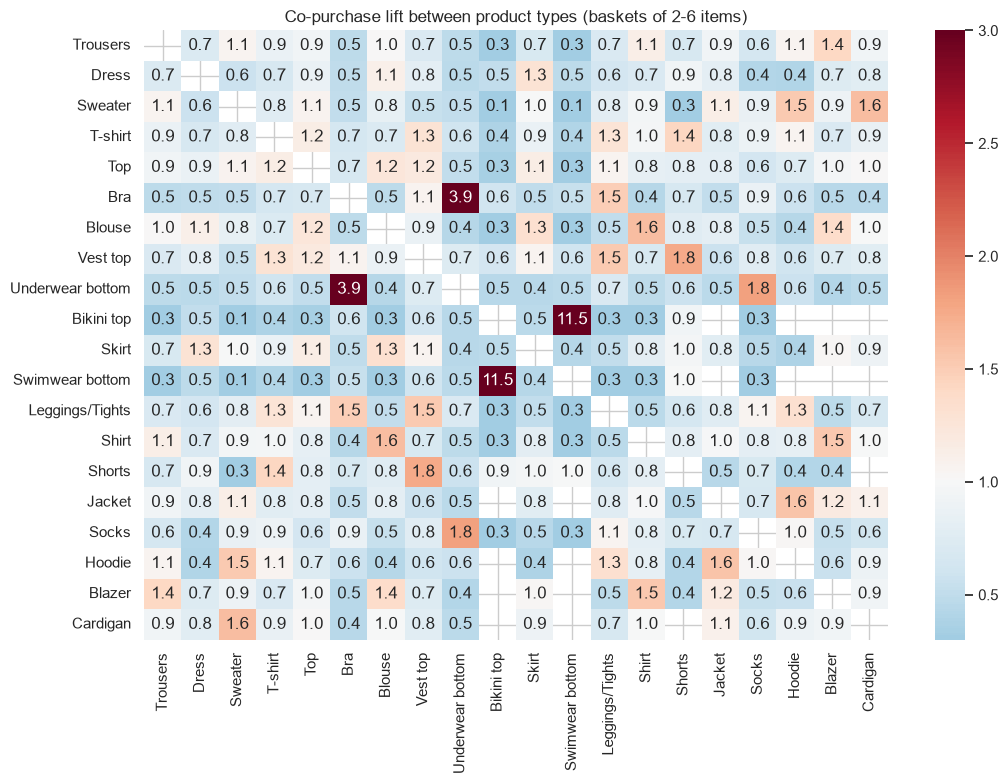

In [12]:
lo, hi = config.LIFT_BASKET_SIZES
window_start = tx["t_dat"].max() - pd.Timedelta(days=(config.WINDOW_DAYS or 10**6) - 1)
tx_win = tx[tx["t_dat"] >= window_start]
baskets, cooc = da.basket_analysis(tx_win, articles, "product_type_name", min_size=lo, max_size=hi)
n_used = int(((baskets["basket_size"] >= lo) & (baskets["basket_size"] <= hi)).sum())
print(f"{n_used:,} baskets with {lo} to {hi} items out of {len(baskets):,} customer-day baskets")
lift = da.lift_matrix(cooc, n_used, min_support=config.LIFT_MIN_SUPPORT)
support = pd.Series(np.diag(cooc.to_numpy()), index=cooc.index).sort_values(ascending=False)
top_types = support.head(20).index
plt.figure(figsize=(11, 8))
sns.heatmap(lift.loc[top_types, top_types], annot=True, fmt=".1f", center=1, cmap="RdBu_r", vmin=0.3, vmax=3)
plt.title("Co-purchase lift between product types (baskets of 2-6 items)")
save_fig("product_type_lift.png")

In [13]:
pairs = lift.stack().rename("lift").reset_index()
pairs.columns = ["type_a", "type_b", "lift"]
pairs = pairs[pairs["type_a"] < pairs["type_b"]]
pairs["baskets"] = [cooc.loc[a, b] for a, b in zip(pairs["type_a"], pairs["type_b"])]
display(pairs.sort_values("lift", ascending=False).head(15))
display(pairs.sort_values("lift").head(10))

,type_a,type_b,lift,baskets
8964,Hair string,Hair ties,19.5581,2288
6195,Necklace,Ring,15.1891,2117
2949,Bikini top,Swimwear bottom,11.4999,144953
4019,Earring,Ring,11.3201,2096
4016,Earring,Necklace,8.7017,5669
723,Swimwear bottom,Swimwear set,8.3598,3206
5632,Hat/beanie,Scarf,8.0797,2574
2349,Pyjama bottom,Pyjama set,7.9773,3737
4885,Coat,Jacket,4.8618,4750
3033,Bikini top,Sarong,4.2819,2533


,type_a,type_b,lift,baskets
773,Sweater,Swimwear bottom,0.1331,4572
2950,Bikini top,Sweater,0.1377,4860
641,Swimwear bottom,Trousers,0.2560,11970
810,Sweater,Swimsuit,0.2565,2008
2945,Bikini top,Trousers,0.2578,12385
2954,Bikini top,Shirt,0.2626,3054
3718,Shorts,Sweater,0.2636,8350
1797,Leggings/Tights,Swimwear bottom,0.2771,3201
1285,Shirt,Swimwear bottom,0.2885,3265
2053,Blouse,Swimwear bottom,0.2922,5328


Lift above 1 means two product types are bought together more than chance. The strongest well-supported pairs are candidate complementary rules for the outfit-aware layer in Week 4; a weak spread of lift around 1 would argue against using this layer.

## 11. Hand-over to Week 3
`data/cleaned/` (interactions, cold-item interactions and `prepared_meta.json`) is what the personalised model uses. Load it with `prep.load_prepared()` and build the shared matrices with `prep.build_experiment(...)`.

## 12. Findings to write up in your own words
1. **Why collapse same-day repeats, and what it changed:** ...
2. **Chosen window, minimum distinct items per user, minimum buyers per item and sample size, with the numbers from the sensitivity table that justify them, and why thresholds are measured on the training period only:** ...
3. **Sparsity of the cleaned matrix and what it means for the models:** ...
4. **Popularity concentration, variant redundancy in top items, and drift over time:** ...
5. **Split design, the cold-item interactions excluded from the main comparison, and how cold start will be handled:** ...
6. **Which baseline variant wins on validation, and its weaknesses (coverage, novelty):** ...
7. **Which product-type pairs show real complementarity, and whether the outfit layer looks worthwhile:** ...